# 01 — EDA of C-MAPSS FD001

Exploration of the **FD001** subset: 1 operating condition, 1 failure mode (HPC degradation).

Goals:
1. number of engines and distribution of their lifetimes;
2. evolution of a few sensors over the cycles;
3. identify constant / non-informative sensors.

> RUL labeling is **not** done here (next step).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.load import SENSOR_COLUMNS, SETTING_COLUMNS, load_cmapss, load_rul

# Clean style: subtle grid, thin lines, no unnecessary frame
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b3ab",
    "axes.labelcolor": "#3d3d3a",
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a",
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical palette, fixed order
NEUTRAL = "#b5b3ab"
pd.set_option("display.width", 140)

## 1. Loading

In [2]:
train = load_cmapss("FD001", "train")
test = load_cmapss("FD001", "test")
rul_test = load_rul("FD001")

print("train:", train.shape, "| test:", test.shape, "| test RUL:", rul_test.shape)
print("missing values (train):", train.isna().sum().sum())
train.head()

train: (20631, 26) | test: (13096, 26) | test RUL: (100,)
missing values (train): 0


,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Engines and lifetimes

The **train** set is *run-to-failure*: each engine is recorded from a healthy state until failure.
Its last cycle = its total lifetime.

In [3]:
lifetime = train.groupby("unit_number")["time_in_cycles"].max().rename("lifetime")

print("train engines:", train["unit_number"].nunique())
print("test engines: ", test["unit_number"].nunique())
lifetime.describe().round(1)

train engines: 100
test engines:  100


count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: lifetime, dtype: float64

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


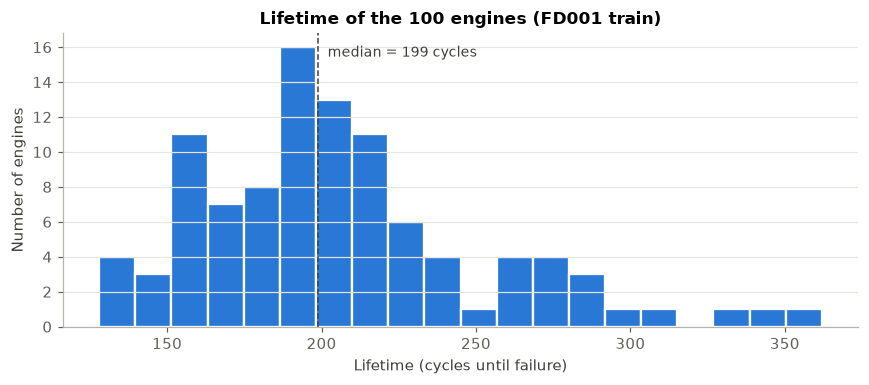

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(lifetime, bins=20, color=SERIES[0], edgecolor="white", linewidth=1.5)
ax.axvline(lifetime.median(), color="#3d3d3a", linestyle="--", linewidth=1)
ax.annotate(f"median = {lifetime.median():.0f} cycles", xy=(lifetime.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color="#3d3d3a", fontsize=9)
ax.set_title("Lifetime of the 100 engines (FD001 train)")
ax.set_xlabel("Lifetime (cycles until failure)")
ax.set_ylabel("Number of engines")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 3. Sensor trajectories

3 engines chosen to cover the range: the shortest-lived, a median one and the longest-lived.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


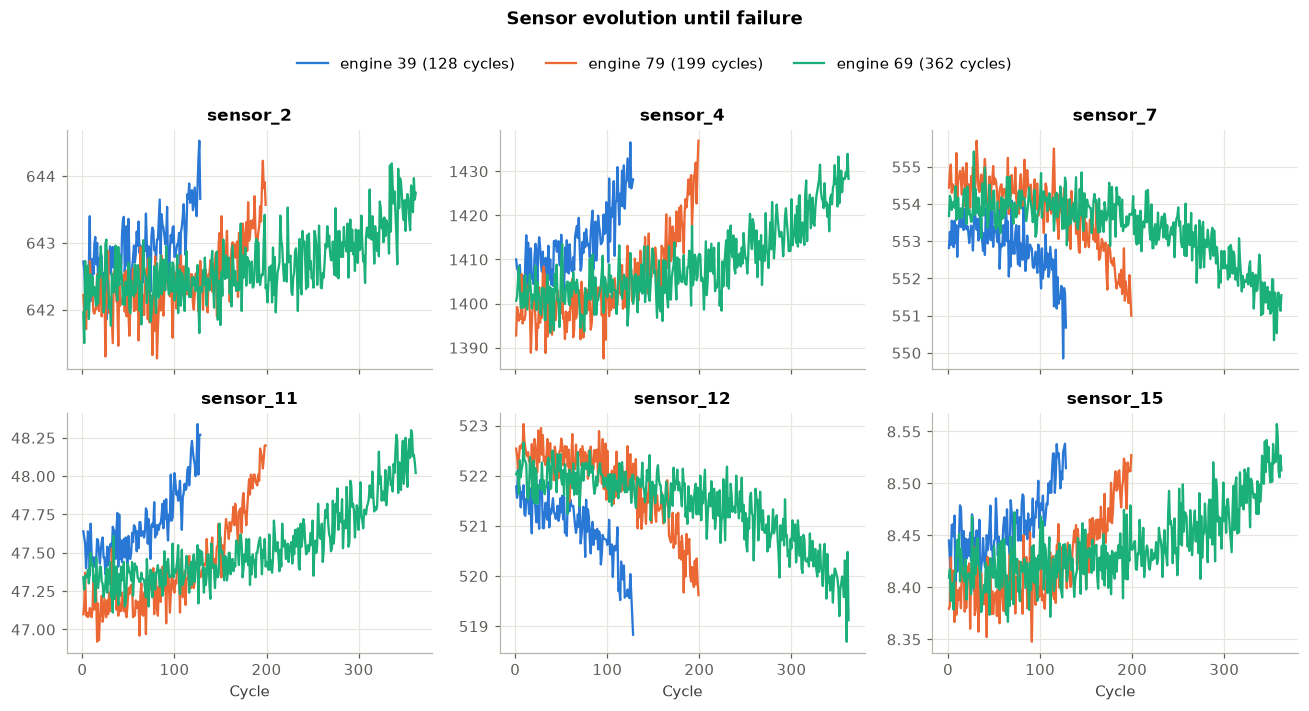

In [5]:
order = lifetime.sort_values()
units = [order.index[0], order.index[len(order) // 2], order.index[-1]]
sensors_to_plot = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, sensor in zip(axes.flat, sensors_to_plot):
    for color, unit in zip(SERIES, units):
        d = train[train["unit_number"] == unit]
        ax.plot(d["time_in_cycles"], d[sensor], color=color, label=f"engine {unit} ({lifetime[unit]} cycles)")
    ax.set_title(sensor)
for ax in axes[1]:
    ax.set_xlabel("Cycle")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Sensor evolution until failure", y=1.07, fontweight="semibold")
plt.tight_layout()
plt.show()

Reading: sensors drift monotonically as failure approaches (upward for 2, 4, 11, 15; downward for 7 and 12).
The signal is noisy early on, then the trend accelerates at end of life: this is the degradation signature.

## 4. Constant / non-informative sensors

Two complementary criteria:
- **variability**: number of distinct values and standard deviation;
- **link with wear**: correlation with the cycle (over the whole train set).

Caution: the coefficient of variation (std / mean) alone is misleading: `sensor_8` and `sensor_13`
have a tiny CV (≈ 3e-5) because their mean value is large (~2388), yet they clearly track degradation.

In [6]:
stats = pd.DataFrame({
    "n_unique": train[SENSOR_COLUMNS].nunique(),
    "std": train[SENSOR_COLUMNS].std(),
    "cv": train[SENSOR_COLUMNS].std() / train[SENSOR_COLUMNS].mean().abs(),
    "corr_cycle": train[SENSOR_COLUMNS].corrwith(train["time_in_cycles"]),
})
stats["drop"] = stats["n_unique"] <= 2
stats.sort_values("n_unique").style.format({"std": "{:.2e}", "cv": "{:.1e}", "corr_cycle": "{:.2f}"})

,n_unique,std,cv,corr_cycle,drop
sensor_1,1,0.00e+00,0.0e+00,nan,True
sensor_5,1,5.33e-15,3.6e-16,0.00,True
sensor_16,1,3.47e-18,1.2e-16,0.00,True
sensor_10,1,0.00e+00,0.0e+00,nan,True
sensor_19,1,0.00e+00,0.0e+00,nan,True
sensor_18,1,0.00e+00,0.0e+00,nan,True
sensor_6,2,1.39e-03,6.4e-05,0.11,True
sensor_17,13,1.55e+00,3.9e-03,0.57,False
sensor_8,53,7.10e-02,3.0e-05,0.48,False
sensor_13,56,7.19e-02,3.0e-05,0.48,False


In [7]:
to_drop = stats.index[stats["drop"]].tolist()
useful = [s for s in SENSOR_COLUMNS if s not in to_drop]
print("Sensors to drop:       ", to_drop)
print("Informative sensors:   ", useful, f"({len(useful)})")

Sensors to drop:        ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Informative sensors:    ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'] (14)


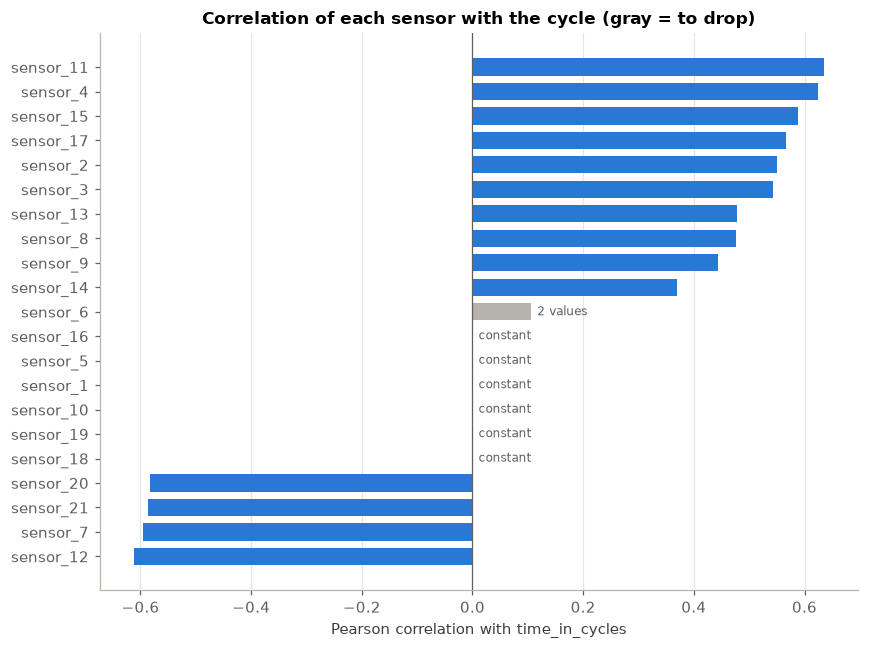

In [8]:
corr = stats["corr_cycle"].fillna(0).sort_values()
colors = [NEUTRAL if s in to_drop else SERIES[0] for s in corr.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=colors, height=0.7)
ax.axvline(0, color="#5f5e5a", linewidth=0.8)
ax.set_axisbelow(True)
for s in to_drop:
    ax.annotate("constant" if stats.loc[s, "n_unique"] == 1 else "2 values",
                xy=(max(corr[s], 0), list(corr.index).index(s)), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color="#5f5e5a")
ax.set_title("Correlation of each sensor with the cycle (gray = to drop)")
ax.set_xlabel("Pearson correlation with time_in_cycles")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Operational settings

FD001 has a single flight condition: the 3 settings barely vary.

In [9]:
train[SETTING_COLUMNS].agg(["nunique", "std", "min", "max"]).T

,nunique,std,min,max
op_setting_1,158.0,0.002187,-0.0087,0.0087
op_setting_2,13.0,0.000293,-0.0006,0.0006
op_setting_3,1.0,0.000000,100.0000,100.0000


## 5. Conclusions

- **100 engines** in train (run-to-failure) and **100** in test (series truncated before failure, true RUL in `RUL_FD001.txt`).
- Lifetime: from **128 to 362 cycles**, median ≈ 199: high variability from one engine to another.
- **To drop (7)**: `sensor_1, 5, 10, 16, 18, 19` (constant) and `sensor_6` (2 values, almost no link with wear).
- **To keep (14)**: `sensor_2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`.
- Operational settings: useless in FD001 (`op_setting_3` is constant, the other two are noise around a single condition).
- `sensor_9` and `sensor_14` show a weaker trend that differs across engines: worth watching during feature selection.